# Lab 4 — ANN do klasyfikacji pokrycia terenu

Celem jest klasyfikacja patchy Sentinel-2 do jednej z dwóch klas: `city` (obszar miejski) albo `forest` (obszar leśny). Notebook realizuje pełny przebieg analizy: najpierw dokładnie definiuje i uruchamia jedną bazową architekturę ANN, a dopiero potem pokazuje pięć osobnych przykładów z celowo zmienioną architekturą lub sposobem optymalizacji. Każda zmiana jest opisana i oceniona na tym samym zbiorze testowym.

## 1. Sformułowanie zadania jako funkcji

Dla każdego patcha obrazu definiujemy wektor cech `x`. Każdy plik TIFF zawiera trzy kanały RGB o rozmiarze 100×100 pikseli. Nie zmniejszamy patcha ani nie dzielimy go na mniejsze obrazy: spłaszczamy bezpośrednio macierz 3×100×100 do wektora 30 000 liczb.

Szukamy funkcji wyuczonej przez sieć:

`fθ: R^30000 → {0, 1}`, gdzie 0 = city, a 1 = forest.

Sieć aproksymuje prawdopodobieństwo `P(y=1 | x)`. Warstwa wyjściowa z funkcją sigmoid zwraca wartość z przedziału [0, 1], a próg 0.5 zamienia ją na etykietę klasy. Jest to binarna klasyfikacja nadzorowana, ponieważ etykieta wynika z folderu, w którym zapisany jest patch.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
    recall_score, roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "train").is_dir():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "Lab4"

TRAIN_DIR = NOTEBOOK_DIR / "train"
TEST_DIR = NOTEBOOK_DIR / "test"
CLASS_NAMES = {"city": 0, "forest": 1}
CLASS_LABELS = ["city", "forest"]

## 2. Inwentaryzacja danych

Etykiety nie są dopisywane ręcznie do nazw plików — wynikają bezpośrednio ze struktury `train/<klasa>` i `test/<klasa>`. Najpierw sprawdzamy liczby plików, aby wykluczyć pomieszanie zbiorów lub klas.

In [2]:
def list_patch_files(split_dir: Path) -> list[Path]:
    files = []
    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Error: {class_dir}")
        files.extend(sorted(class_dir.glob("*.tif")))
    return files

inventory_rows = []
for split_name, split_dir in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    for class_name, class_id in CLASS_NAMES.items():
        paths = sorted((split_dir / class_name).glob("*.tif"))
        inventory_rows.append({
            "split": split_name,
            "class": class_name,
            "label": class_id,
            "patches": len(paths),
        })

inventory = pd.DataFrame(inventory_rows)
display(inventory)

,split,class,label,patches
0,train,city,0,158
1,train,forest,1,658
2,test,city,0,40
3,test,forest,1,163


## 3. Sprawdzenie formatu GeoTIFF-ów i przykładowa wizualizacja

Polecenie dopuszcza patch 200×200, ale rzeczywiste pliki dostarczone w `Lab4/train` i `Lab4/test` mają 100×100 pikseli. Zamiast dopisywać sztuczne piksele lub interpolować dane, używamy dokładnie tych patchy. Dalsza agregacja 5×5 zmniejsza tylko wymiar cech i nie zmienia etykiety.

city_r0000_c0100.tif: shape=(3, 100, 100), dtype=float32, CRS=EPSG:32634, min=0.0157, max=0.4652
forest_r0000_c0200.tif: shape=(3, 100, 100), dtype=float32, CRS=EPSG:32634, min=0.0102, max=0.0700


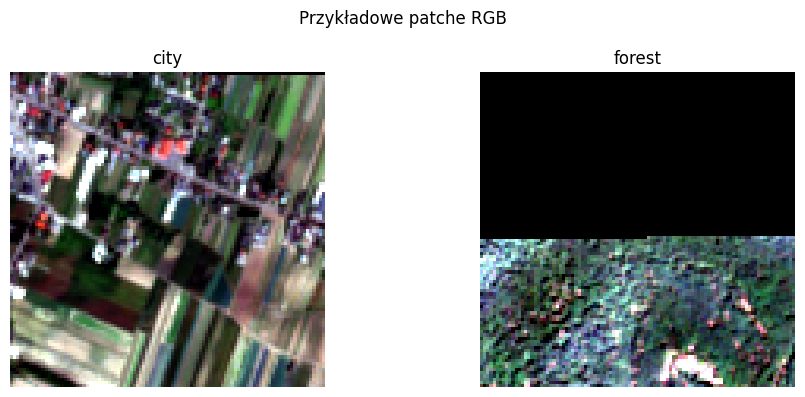

In [3]:
def read_patch(path: Path) -> np.ndarray:
    with rasterio.open(path) as src:
        image = src.read().astype(np.float32)
        if src.count != 3:
            raise ValueError(f"{path.name}: oczekiwano 3 kanałów, jest {src.count}")
        if image.ndim != 3 or image.shape[1] != image.shape[2]:
            raise ValueError(f"{path.name}: nieoczekiwany kształt {image.shape}")
        return image

example_paths = [
    TRAIN_DIR / "city" / "city_r0000_c0100.tif",
    TRAIN_DIR / "forest" / "forest_r0000_c0200.tif",
]
def rgb_preview(image: np.ndarray) -> np.ndarray:
    """Przygotuj stabilny podgląd RGB bez wpływu NaN na imshow."""
    rgb = np.moveaxis(image, 0, -1)
    preview = np.zeros(rgb.shape, dtype=np.float32)
    for channel in range(rgb.shape[-1]):
        band = rgb[..., channel]
        finite_values = band[np.isfinite(band)]
        if finite_values.size == 0:
            continue
        low, high = np.percentile(finite_values, [2, 98])
        if high <= low:
            high = low + 1e-6
        safe_band = np.nan_to_num(band, nan=low, posinf=high, neginf=low)
        preview[..., channel] = np.clip((safe_band - low) / (high - low), 0, 1)
    return preview

for path in example_paths:
    with rasterio.open(path) as src:
        sample = src.read()
        print(
            f"{path.name}: shape={sample.shape}, dtype={sample.dtype}, "
            f"CRS={src.crs}, min={np.nanmin(sample):.4f}, max={np.nanmax(sample):.4f}"
        )

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, path in zip(axes, example_paths):
    ax.imshow(rgb_preview(read_patch(path)))
    ax.set_title(path.parent.name)
    ax.axis("off")
fig.suptitle("Przykładowe patche RGB")
plt.tight_layout()
plt.show()

## 4. Przygotowanie cech wejściowych

Nie wykonujemy żadnego cropowania, dzielenia ani downsamplingu. Patch pozostaje w całości jako 3×100×100, a wejście ANN ma 30 000 cech — po kolei wszystkie wartości kanałów RGB. Skalowanie `StandardScaler` jest dopasowywane wyłącznie do `train`, a następnie stosowane do `test`, więc statystyki testowe nie przeciekają do uczenia.

In [4]:
def patch_to_features(path: Path) -> np.ndarray:
    image = read_patch(path)  # (channels, height, width)
    channels, height, width = image.shape
    if (channels, height, width) != (3, 100, 100):
        raise ValueError(f"{path.name}: oczekiwano (3, 100, 100), jest {image.shape}")
    return image.reshape(-1).astype(np.float32)

def build_dataset(split_dir: Path) -> tuple[np.ndarray, np.ndarray, list[Path]]:
    paths = list_patch_files(split_dir)
    features = np.vstack([patch_to_features(path) for path in paths])
    labels = np.array([CLASS_NAMES[path.parent.name] for path in paths], dtype=np.int64)
    return features, labels, paths

X_train, y_train, train_paths = build_dataset(TRAIN_DIR)
X_test, y_test, test_paths = build_dataset(TEST_DIR)

# W danych występują niektóre wartości NaN. Mediany liczymy tylko z train,
# a następnie używamy ich do uzupełnienia obu zbiorów.
train_invalid = ~np.isfinite(X_train)
test_invalid = ~np.isfinite(X_test)
X_train_for_median = X_train.copy()
X_train_for_median[train_invalid] = np.nan
feature_medians = np.nanmedian(X_train_for_median, axis=0)
if not np.all(np.isfinite(feature_medians)):
    raise ValueError("Co najmniej jedna cecha jest pusta w całym train.")
X_train = np.where(train_invalid, feature_medians, X_train).astype(np.float32)
X_test = np.where(test_invalid, feature_medians, X_test).astype(np.float32)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print(f"Uzupełnione wartości: train={train_invalid.sum()}, test={test_invalid.sum()}")
print(f"Zakres cech train po imputacji: [{X_train.min():.4f}, {X_train.max():.4f}]")
assert X_train.shape[1] == 3 * 100 * 100
assert X_train.shape[0] == len(train_paths) and X_test.shape[0] == len(test_paths)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

X_train: (816, 30000), y_train: (816,)
X_test:  (203, 30000), y_test:  (203,)
Uzupełnione wartości: train=886329, test=274806
Zakres cech train po imputacji: [0.0072, 0.8264]


## 5. Bazowa architektura ANN — najpierw jeden model

W tej sekcji trenujemy **dokładnie jedną** sieć. Jest to punkt odniesienia dla wszystkich późniejszych eksperymentów, dlatego nie zmieniamy tu liczby warstw ani neuronów.

### Schemat bazowy

`30000 → 16 → 1`

- **Wejście — 30 000 wartości:** każdy patch ma kształt `3 × 100 × 100`, więc po spłaszczeniu otrzymujemy 30 000 cech. Kolejność wartości jest taka sama dla każdego obrazu.
- **Jedna warstwa ukryta — 16 neuronów ReLU:** warstwa uczy się nieliniowych kombinacji cech pikselowych. ReLU ma postać `max(0, x)` i pozwala modelowi uczyć się nieliniowej granicy między klasami.
- **Wyjście — jeden neuron:** dla klasyfikacji binarnej `MLPClassifier` używa wyjścia logistycznego, równoważnego funkcji sigmoid. Wynik jest prawdopodobieństwem klasy `forest`, a próg 0.5 zamienia prawdopodobieństwo na etykietę `city` albo `forest`.
- **Skalowanie:** `StandardScaler` jest dopasowywany wyłącznie na `X_train`, a następnie używany bez ponownego dopasowania na `X_test`.
- **Uczenie:** używamy optymalizatora Adam, entropii krzyżowej jako funkcji kosztu, `early_stopping=True` i stałego `random_state=42`. Dzięki temu późniejsze różnice wynikają z konfiguracji modelu, a nie z innego losowania danych.

Poniższa komórka tworzy pomocniczą funkcję, ale wywołuje ją tylko raz — dla bazowej architektury. Raportujemy accuracy, balanced accuracy, precision, recall, F1 i ROC-AUC, ponieważ klasy `city` i `forest` są niezrównoważone.

In [5]:
BASELINE_NAME = "baza: 16 ReLU + Adam"
baseline_config = {
    "hidden_layer_sizes": (16,),
    "activation": "relu",
    "solver": "adam",
    "alpha": 1e-4,
    "learning_rate_init": 1e-3,
    "max_iter": 300,
}

def fit_and_evaluate(name: str, config: dict):
    """Trenuje jeden MLP i zwraca model, metryki oraz krzywą loss."""
    config_for_mlp = {
        key: value for key, value in config.items()
        if key != "name"
    }
    config_for_mlp.update({
        "early_stopping": True,
        "validation_fraction": 0.15,
        "n_iter_no_change": 25,
        "random_state": RANDOM_STATE,
    })

    model = make_pipeline(
        StandardScaler(),
        MLPClassifier(**config_for_mlp),
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    mlp = model.named_steps["mlpclassifier"]

    row = {
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
        "precision_forest": precision_score(y_test, predictions, zero_division=0),
        "recall_forest": recall_score(y_test, predictions, zero_division=0),
        "f1_forest": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "iterations": mlp.n_iter_,
        "final_loss": mlp.loss_,
    }
    return model, row, mlp.loss_curve_

# To jest jedyne uruchomienie modelu w sekcji bazowej.
baseline_model, baseline_row, baseline_history = fit_and_evaluate(
    BASELINE_NAME,
    baseline_config,
)

models = {BASELINE_NAME: baseline_model}
histories = {BASELINE_NAME: baseline_history}
metrics_rows = [baseline_row]

baseline_results = pd.DataFrame([baseline_row])
print("Wynik jednej bazowej architektury:")
display(
    baseline_results.style.format({
        column: "{:.4f}"
        for column in baseline_results.columns
        if column not in {"model", "iterations"}
    })
)

Wynik jednej bazowej architektury:


,model,accuracy,balanced_accuracy,precision_forest,recall_forest,f1_forest,roc_auc,iterations,final_loss
0,baza: 16 ReLU + Adam,0.9704,0.9816,1.0000,0.9632,0.9812,1.0000,27,0.0153


## 6. Dopiero teraz: przykłady ze zmienioną architekturą

Bazowy model został już wytrenowany i zapisany jako punkt odniesienia. Teraz uruchamiamy **pięć odrębnych eksperymentów**. W każdym eksperymencie zmieniamy wyraźnie wskazany element, a przygotowanie danych, podział na train/test, skalowanie i ziarno losowe pozostają takie same.

| Wariant | Schemat / ustawienie | Co zmieniamy i po co? |
|---|---|---|
| 1. Szerszy | `30000 → 64 → 1`, ReLU, Adam | Cztery razy więcej neuronów w warstwie ukrytej. Model ma większą pojemność i może nauczyć się bardziej szczegółowej granicy. |
| 2. Głębszy | `30000 → 64 → 32 → 1`, ReLU, Adam | Dodajemy drugą warstwę ukrytą. Sprawdzamy, czy hierarchiczne przekształcenia cech pomagają bardziej niż sama szerokość. |
| 3. Trzy warstwy | `30000 → 64 → 32 → 16 → 1`, ReLU, Adam | Dodajemy kolejną warstwę i stopniowo zmniejszamy liczbę neuronów, tworząc węższy „lejek” reprezentacji. |
| 4. Inna aktywacja | `30000 → 32 → 1`, tanh, Adam | Zostawiamy jedną warstwę, ale zastępujemy ReLU funkcją `tanh`. To test wpływu funkcji aktywacji. |
| 5. Inny optymalizator | `30000 → 32 → 1`, ReLU, SGD | Zmieniamy Adam na SGD z momentum i adaptacyjnym learning rate. To test wpływu sposobu aktualizacji wag. |

Każdy wariant jest oceniany identycznie jak baza. Po zakończeniu tabela zawiera więc sześć modeli: bazę oraz pięć modyfikacji. Najważniejszą miarą wyboru jest `balanced_accuracy`, bo zwykłe accuracy może być zawyżone przez liczniejszą klasę `forest`.

Porównanie bazy i pięciu zmienionych konfiguracji:


,model,accuracy,balanced_accuracy,precision_forest,recall_forest,f1_forest,roc_auc,iterations,final_loss
0,wariant 2: 64-32 ReLU + Adam,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,35,0.0002
1,wariant 5: 32 ReLU + SGD,0.9951,0.9969,1.0000,0.9939,0.9969,1.0000,209,0.0020
2,wariant 3: 64-32-16 ReLU + Adam,0.9901,0.9939,1.0000,0.9877,0.9938,1.0000,32,0.0001
3,wariant 1: 64 ReLU + Adam,0.9852,0.9908,1.0000,0.9816,0.9907,1.0000,31,0.0001
4,baza: 16 ReLU + Adam,0.9704,0.9816,1.0000,0.9632,0.9812,1.0000,27,0.0153
5,wariant 4: 32 tanh + Adam,0.9704,0.9816,1.0000,0.9632,0.9812,0.9969,27,0.1225


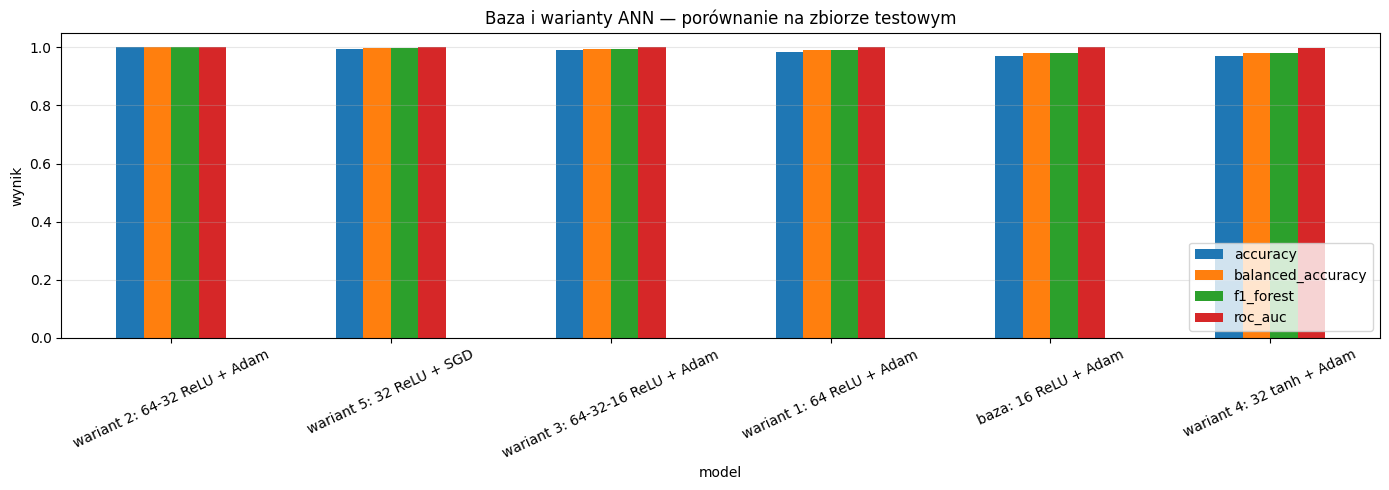

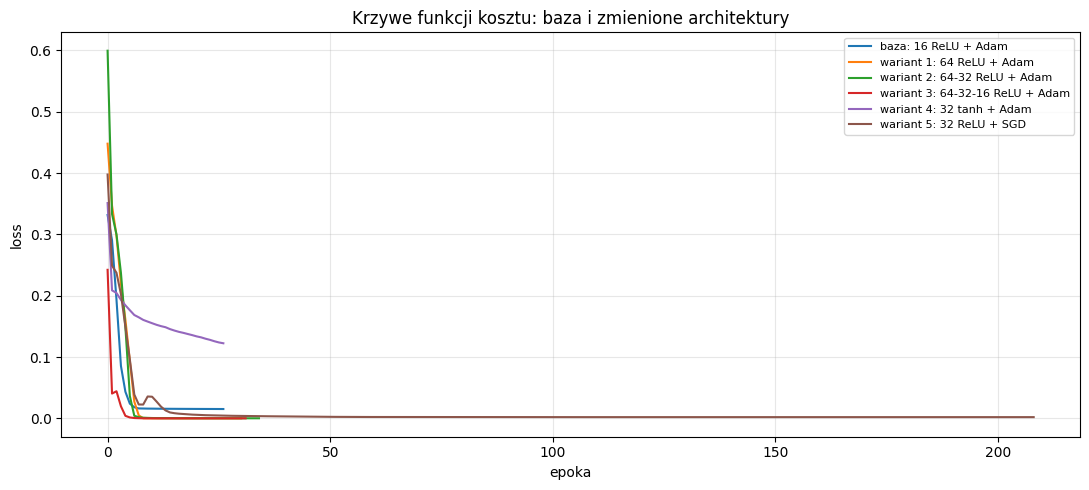

In [6]:
architecture_variants = [
    {
        "name": "wariant 1: 64 ReLU + Adam",
        "hidden_layer_sizes": (64,),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "wariant 2: 64-32 ReLU + Adam",
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "wariant 3: 64-32-16 ReLU + Adam",
        "hidden_layer_sizes": (64, 32, 16),
        "activation": "relu",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "wariant 4: 32 tanh + Adam",
        "hidden_layer_sizes": (32,),
        "activation": "tanh",
        "solver": "adam",
        "alpha": 1e-4,
        "learning_rate_init": 1e-3,
        "max_iter": 300,
    },
    {
        "name": "wariant 5: 32 ReLU + SGD",
        "hidden_layer_sizes": (32,),
        "activation": "relu",
        "solver": "sgd",
        "alpha": 1e-4,
        "learning_rate_init": 1e-2,
        "learning_rate": "adaptive",
        "momentum": 0.9,
        "max_iter": 400,
    },
]

# Każdy wariant jest trenowany dopiero po wykonaniu eksperymentu bazowego.
for config in architecture_variants:
    model, row, loss_curve = fit_and_evaluate(
        config["name"],
        config,
    )
    models[config["name"]] = model
    histories[config["name"]] = loss_curve
    metrics_rows.append(row)

results = (
    pd.DataFrame(metrics_rows)
    .sort_values("balanced_accuracy", ascending=False)
    .reset_index(drop=True)
)

print("Porównanie bazy i pięciu zmienionych konfiguracji:")
display(
    results.style.format({
        column: "{:.4f}"
        for column in results.columns
        if column not in {"model", "iterations"}
    })
)

# Wykresy pokazują zarówno jakość predykcji, jak i przebieg uczenia.
plot_metrics = results.set_index("model")[
    ["accuracy", "balanced_accuracy", "f1_forest", "roc_auc"]
]
ax = plot_metrics.plot(
    kind="bar",
    figsize=(14, 5),
    ylim=(0, 1.05),
    rot=25,
)
ax.set_ylabel("wynik")
ax.set_title("Baza i warianty ANN — porównanie na zbiorze testowym")
ax.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
for name, loss_curve in histories.items():
    ax.plot(loss_curve, label=name)
ax.set_xlabel("epoka")
ax.set_ylabel("loss")
ax.set_title("Krzywe funkcji kosztu: baza i zmienione architektury")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Szczegółowa ocena najlepszego wariantu

W tabeli `results` znajdują się baza oraz wszystkie pięć zmienionych konfiguracji. Wybieramy model z najwyższą `balanced_accuracy`, a następnie pokazujemy macierz pomyłek i raport klasyfikacji. Macierz pozwala rozróżnić dwa rodzaje błędu: miasto rozpoznane jako las oraz las rozpoznany jako miasto.

Najlepszy wariant według balanced accuracy: wariant 2: 64-32 ReLU + Adam
ROC-AUC: 1.0000

Raport klasyfikacji:
              precision    recall  f1-score   support

        city     1.0000    1.0000    1.0000        40
      forest     1.0000    1.0000    1.0000       163

    accuracy                         1.0000       203
   macro avg     1.0000    1.0000    1.0000       203
weighted avg     1.0000    1.0000    1.0000       203



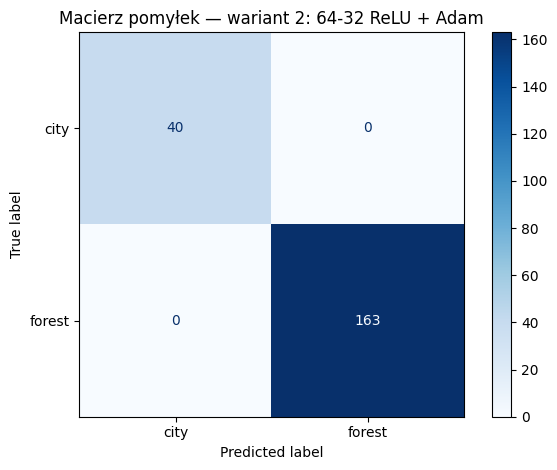

In [7]:
best_name = results.iloc[0]["model"]
best_model = models[best_name]
best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]
best_cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])

print(f"Najlepszy wariant według balanced accuracy: {best_name}")
print(f"ROC-AUC: {roc_auc_score(y_test, best_probabilities):.4f}")
print("\nRaport klasyfikacji:")
print(classification_report(y_test, best_predictions, target_names=CLASS_LABELS, digits=4, zero_division=0))

disp = ConfusionMatrixDisplay(confusion_matrix=best_cm, display_labels=CLASS_LABELS)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Macierz pomyłek — {best_name}")
plt.tight_layout()
plt.show()

## 8. Przykładowe predykcje i wnioski

Poniżej pokazujemy kilka patchy testowych razem z etykietą rzeczywistą, predykcją i prawdopodobieństwem klasy `forest`. Wybrany model jest najlepszym modelem spośród bazy i pięciu opisanych wariantów. Ostatni wydruk automatycznie podsumowuje wynik uzyskany w tym konkretnym uruchomieniu notebooka.

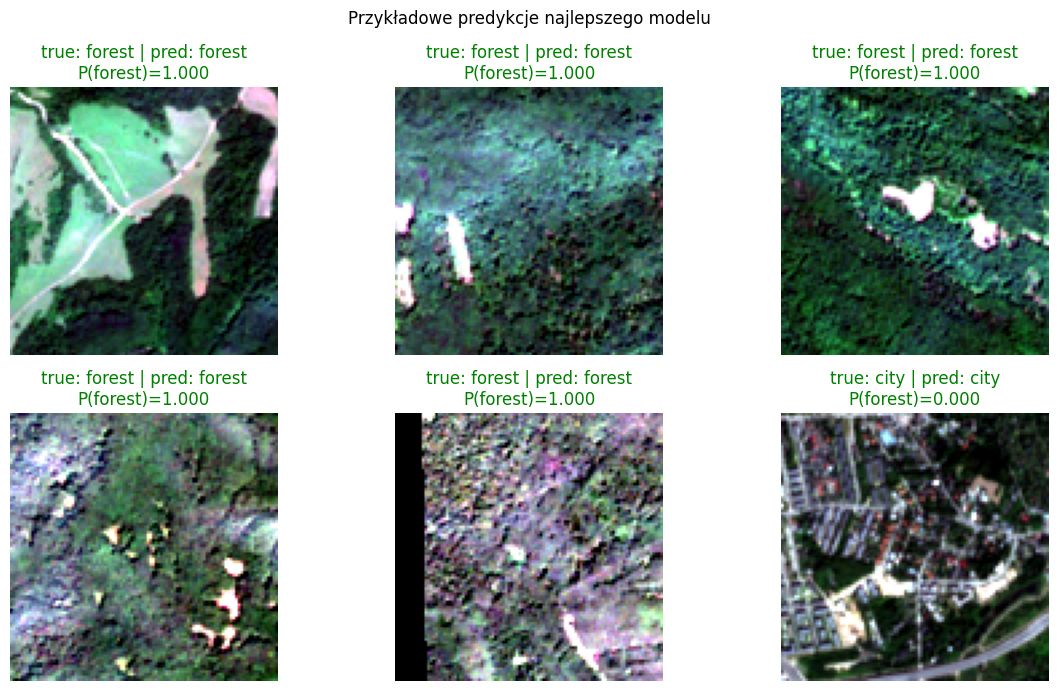

WNIOSKI
1. Najlepszy z pięciu wariantów: wariant 2: 64-32 ReLU + Adam.
2. Accuracy = 1.0000, balanced accuracy = 1.0000, F1(forest) = 1.0000.
3. Zwiększenie liczby warstw/neuronów lub zmiana aktywacji/optimizera nie gwarantuje poprawy — wybór opieramy na wynikach testowych.
4. Wynik dotyczy dostarczonych patchy i ich folderowego podziału train/test; przy innym obszarze geograficznym należy ponownie ocenić generalizację.


In [8]:
rng = np.random.default_rng(RANDOM_STATE)
sample_indices = rng.choice(len(test_paths), size=min(6, len(test_paths)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, index in zip(axes.ravel(), sample_indices):
    path = test_paths[index]
    ax.imshow(rgb_preview(read_patch(path)))
    true_name = CLASS_LABELS[y_test[index]]
    pred_name = CLASS_LABELS[best_predictions[index]]
    colour = "green" if true_name == pred_name else "red"
    ax.set_title(f"true: {true_name} | pred: {pred_name}\nP(forest)={best_probabilities[index]:.3f}", color=colour)
    ax.axis("off")
plt.suptitle("Przykładowe predykcje najlepszego modelu")
plt.tight_layout()
plt.show()

best_row = results.iloc[0]
print("WNIOSKI")
print(f"1. Najlepszy z pięciu wariantów: {best_name}.")
print(f"2. Accuracy = {best_row['accuracy']:.4f}, balanced accuracy = {best_row['balanced_accuracy']:.4f}, F1(forest) = {best_row['f1_forest']:.4f}.")
print("3. Zwiększenie liczby warstw/neuronów lub zmiana aktywacji/optimizera nie gwarantuje poprawy — wybór opieramy na wynikach testowych.")
print("4. Wynik dotyczy dostarczonych patchy i ich folderowego podziału train/test; przy innym obszarze geograficznym należy ponownie ocenić generalizację.")